# Trabalho Indívidual

**Exploração de GANs e Autoencoders**

Este notebook implementa Image Inpainting via Context Encoders. O objetivo é treinar uma rede neuronal para reconstruir regiões apagadas de imagens de rostos, para isso utilizei:
- **Gerador** do tipo U-Net (Context Encoder) — responsável por "inventar" o conteúdo em falta
- **Discriminador** do tipo PatchGAN — responsável por avaliar se o remendo é convincente
- **Três funções de perda distintas**: L2 Loss, GAN Loss e Joint Loss — para comparar o impacto de cada abordagem

Referência principal: Pathak et al., *"Context Encoders: Feature Learning by Inpainting"*, CVPR 2016.



## 1. Instalação de Dependências

In [1]:
!pip install torch torchvision matplotlib numpy Pillow scikit-image -q

## 2. Imports e Configuração Inicial

A seed fixa (`SEED=42`) de forma a garantir que os resultados são reprodutíveis entre execuções. E verificar se estava a usar o GPU correto do meu portátil.


In [3]:
import os
import time
import math
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.utils as vutils

from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'A usar: {DEVICE}')
if DEVICE.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')

A usar: cuda
GPU: NVIDIA GeForce RTX 3060 Laptop GPU


## 3. Dataset CelebA

Utilizei o dataset **CelebA** (Large-scale CelebFaces Attributes), que contém mais de 200 000 fotografias de rostos de celebridades alinhadas e recortadas. Optei por este dataset pois os rostos estão sempre centrados, o que facilita a aprendizagem do contexto espacial.



In [4]:
DATA_DIR = './img_align_celeba/img_align_celeba'  

if os.path.exists(DATA_DIR):
    files = os.listdir(DATA_DIR)
    print(f'Dataset encontrado: {len(files)} imagens')
else:
    print('AVISO: Pasta não encontrada. Confirma o caminho.')

Dataset encontrado: 202599 imagens


## 4. Hiperparâmetros e Modo de Execução

O notebook tem dois modos de execução controlados pela flag `DEBUG`:

- **`DEBUG=True`** — usa imagens a 64 px, apenas 2000 imagens e 10 épocas. Serviu exclusivamente como teste para validar que o pipeline funciona sem erros antes de comprometer horas de GPU.                                                                                                               
- **`DEBUG=False`** — configuração do treino final: 128 px, 20 000 imagens, 150 épocas. Foi esta configuração que gerou os resultados apresentados na secção de discussão.

Relativamente ao peso adversarial: o paper original de Pathak et al. usa `λ_adv=0.001`, calibrado para treinos de vários dias com datasets completos. Para  as 150 épocas que fui executando, esse valor revelou-se demasiado baixo pois a Joint Loss tornava-se indistinguível da L2. Após alguns testes `λ_adv=0.002`, foi o valor que se mostrou suficiente para ter impacto real sem desestabilizar o treino.


In [5]:
# ============================================================
# MODO DE EXECUÇÃO
# ============================================================
DEBUG = False  

if DEBUG:
    IMG_SIZE     = 64
    MASK_SIZE    = 32
    NUM_IMAGES   = 2000
    BATCH_SIZE   = 64       
    NUM_WORKERS  = 4
    NUM_EPOCHS   = 10
else:
    IMG_SIZE     = 128
    MASK_SIZE    = 64
    NUM_IMAGES   = 20000
    BATCH_SIZE   = 64
    NUM_WORKERS  = 4
    NUM_EPOCHS   = 150

# --- Treino ---
LR_G         = 2e-4
LR_D         = 1e-4     
BETA1        = 0.5
BETA2        = 0.999
LAMBDA_REC   = 0.99
LAMBDA_ADV   = 0.002

# --- Canais ---
NC           = 3
NGF          = 64
NDF          = 64

# --- Output ---
SAVE_ROOT    = './outputs'
os.makedirs(SAVE_ROOT, exist_ok=True)

print(f'Modo: {"DEBUG (rápido)" if DEBUG else "FINAL (completo)"}')
print(f'  IMG_SIZE={IMG_SIZE}  NUM_IMAGES={NUM_IMAGES}  NUM_EPOCHS={NUM_EPOCHS}  BATCH_SIZE={BATCH_SIZE}')
print(f'  LAMBDA_REC={LAMBDA_REC}  LAMBDA_ADV={LAMBDA_ADV}')

Modo: FINAL (completo)
  IMG_SIZE=128  NUM_IMAGES=20000  NUM_EPOCHS=150  BATCH_SIZE=64
  LAMBDA_REC=0.99  LAMBDA_ADV=0.002


## 5. Dataset e criação das Máscaras

As imagens CelebA (originalmente 178×218 px) são pré-processadas com `CenterCrop(178)` antes do `Resize`.Esta ordem é importante pois o crop primeiro isola o rosto removendo o fundo excessivo, e só depois o resize escala para a resolução alvo. Se inverte-se a ordem produziria imagens distorcidas.

Em vez de máscaras centrais fixas (como no paper original), optei por **máscaras aleatórias** que podem aparecer em qualquer posição da imagem. Optei desta forma com o intuito de obriga o modelo a aprender a reconstruir não só o centro da face, mas também cabelo, fundo e contornos, tornando o problema mais difícil e o modelo mais robusto.

As coordenadas exatas de cada máscara `(x1, y1, x2, y2)` são devolvidas pelo dataset e usadas na avaliação para restringir o cálculo de PSNR/SSIM à região efetivamente reconstruída.


In [6]:
class CelebAInpaintingDataset(Dataset):
    def __init__(self, data_dir, num_images=None, img_size=128, mask_size=64, mask_type='random'):
        self.data_dir  = data_dir
        self.img_size  = img_size
        self.mask_size = mask_size
        self.mask_type = mask_type  # 'center' ou 'random'

        all_files = sorted([
            f for f in os.listdir(data_dir)
            if f.lower().endswith(('.jpg', '.png', '.jpeg'))
        ])

        if num_images:
            all_files = all_files[:num_images]
        self.files = all_files

        self.transform = transforms.Compose([
            transforms.CenterCrop(178),
            transforms.Resize((img_size, img_size)),
            transforms.ToTensor(),
            transforms.Normalize([0.5]*3, [0.5]*3)  # normaliza para [-1, 1]
        ])

    def apply_mask(self, img_tensor):
        """Aplica máscara aleatória à imagem."""
        masked = img_tensor.clone()
        mask   = torch.zeros(1, self.img_size, self.img_size)

        if self.mask_type == 'center':
            x1 = (self.img_size - self.mask_size) // 2
            y1 = (self.img_size - self.mask_size) // 2
            x2 = x1 + self.mask_size
            y2 = y1 + self.mask_size
        else:
            x1 = random.randint(0, self.img_size - self.mask_size)
            y1 = random.randint(0, self.img_size - self.mask_size)
            x2 = x1 + self.mask_size
            y2 = y1 + self.mask_size

        masked[:, y1:y2, x1:x2] = -1.0
        mask[:, y1:y2, x1:x2]   = 1.0

        return masked, mask, (x1, y1, x2, y2)

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        img_path = os.path.join(self.data_dir, self.files[idx])
        img      = Image.open(img_path).convert('RGB')
        original = self.transform(img)
        masked, mask, coords = self.apply_mask(original)
        return masked, original, mask, coords


def get_dataloaders(data_dir, num_images, img_size, mask_size, batch_size, num_workers):
    dataset = CelebAInpaintingDataset(
        data_dir=data_dir,
        num_images=num_images,
        img_size=img_size,
        mask_size=mask_size,
        mask_type='random'
    )

    val_size   = max(int(0.1 * len(dataset)), batch_size)
    train_size = len(dataset) - val_size
    train_ds, val_ds = torch.utils.data.random_split(dataset, [train_size, val_size])

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                              num_workers=num_workers, pin_memory=True, persistent_workers=(num_workers > 0))
    val_loader   = DataLoader(val_ds, batch_size=batch_size, shuffle=False,
                              num_workers=num_workers, pin_memory=True, persistent_workers=(num_workers > 0))

    print(f'Treino: {train_size} imagens | Validação: {val_size} imagens')
    return train_loader, val_loader


train_loader, val_loader = get_dataloaders(
    DATA_DIR, NUM_IMAGES, IMG_SIZE, MASK_SIZE, BATCH_SIZE, NUM_WORKERS
)

Treino: 18000 imagens | Validação: 2000 imagens


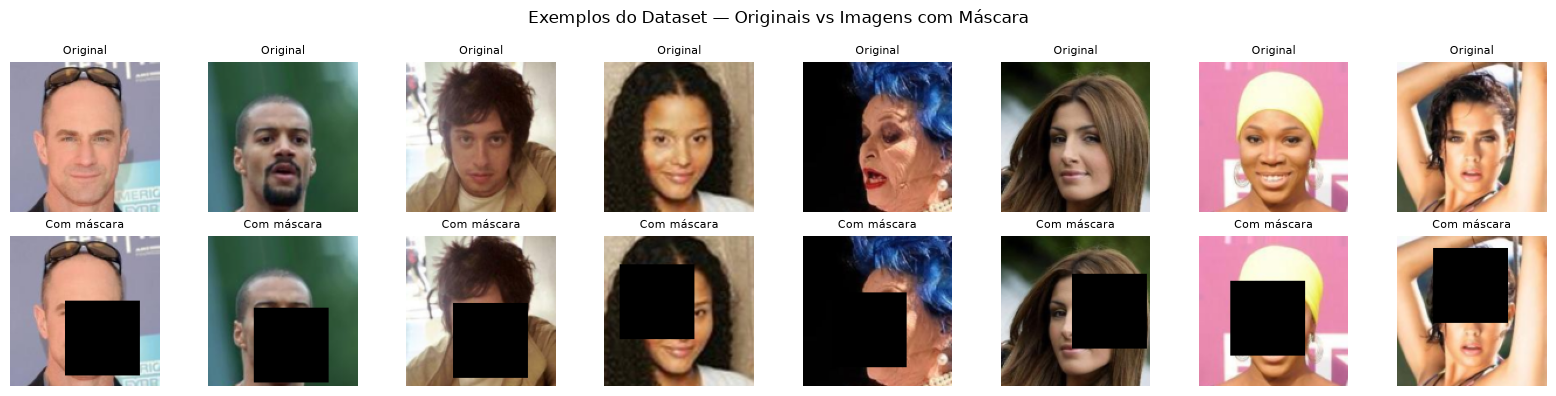

In [7]:
# Visualizar exemplos do dataset com as máscaras
def denorm(tensor):
    return (tensor * 0.5 + 0.5).clamp(0, 1)

masked_imgs, originals, masks, _ = next(iter(train_loader))

fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i in range(8):
    axes[0, i].imshow(denorm(originals[i]).permute(1, 2, 0).numpy())
    axes[0, i].set_title('Original', fontsize=8)
    axes[0, i].axis('off')

    axes[1, i].imshow(denorm(masked_imgs[i]).permute(1, 2, 0).numpy())
    axes[1, i].set_title('Com máscara', fontsize=8)
    axes[1, i].axis('off')

plt.suptitle('Exemplos do Dataset — Originais vs Imagens com Máscara', fontsize=12)
plt.tight_layout()
plt.savefig(f'{SAVE_ROOT}/dataset_examples.png', dpi=100, bbox_inches='tight')
plt.show()

## 6. Arquitetura — Encoder (U-Net) + PatchGAN

### Encoder com estrutura U-Net

O gerador segue a arquitetura encoder-bottleneck-decoder com skip connections, inspirada na U-Net. O encoder comprime a imagem mascarada até uma representação latente compacta. O decoder reconstrói a imagem a partir dessa representação, usando as skip connections para recuperar detalhes espaciais de alta resolução.

O número de blocos adapta-se automaticamente ao `IMG_SIZE`: para 64 px são criados menos blocos do que para 128 px, mantendo sempre a proporção correta entre capacidade e resolução.

Uma decisão importante no decoder foi substituir o `ConvTranspose2d` por `Upsample(nearest) + Conv2d`. O `ConvTranspose2d` com kernel=4 e stride=2 produzia sobreposições desiguais durante o upsampling. Alguns pixéis do output recebiam contribuições de mais filtros do que outros, o que acabava por criar o padrão de grelha ("checkerboard") que foi verificado nos meus primeiros testes. A combinação Upsample + Conv evita este problema mantendo a mesma capacidade de upsampling.

### PatchGAN

O PatchGAN não avalia a imagem como um todo, divide-a implicitamente em patches e classifica cada um como real ou falso. Isto força o gerador a produzir texturas localmente convincentes, não apenas globalmente coerentes.

O problema da versão anterior era que o campo recetivo era fixo em 94×94 px e num tamanho de imagem de 64×64, isto significava que o discriminador via a imagem quase inteira em cada patch, comportando-se de facto como um discriminador global. O resultado foram os artefactos "tartan" coloridos observados com a Joint Loss.

A solução foi calcular o número de camadas com stride=2 em função do `IMG_SIZE`, garantindo que o campo recetivo se mantém sempre proporcional à resolução independentemente do tamanho da imagem.


In [10]:
class DownBlock(nn.Module):
    """Bloco de downsampling do Encoder."""
    def __init__(self, in_ch, out_ch, use_bn=True):
        super().__init__()
        layers = [nn.Conv2d(in_ch, out_ch, 4, stride=2, padding=1, bias=not use_bn)]
        if use_bn:
            layers.append(nn.BatchNorm2d(out_ch))
        layers.append(nn.LeakyReLU(0.2, inplace=True))
        self.block = nn.Sequential(*layers)

    def forward(self, x):
        return self.block(x)


class UpBlock(nn.Module):
    """Bloco de upsampling do Decoder com skip connection."""
    def __init__(self, in_ch, out_ch, dropout=False):
        super().__init__()
        layers = [
            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.Conv2d(in_ch, out_ch, 3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        ]
        if dropout:
            layers.append(nn.Dropout(0.5))
        self.block = nn.Sequential(*layers)

    def forward(self, x, skip):
        x = self.block(x)
        return torch.cat([x, skip], dim=1)


class ContextEncoder(nn.Module):
    """Gerador U-Net para Image Inpainting."""
    def __init__(self, nc=3, ngf=64, img_size=128):
        super().__init__()

        assert img_size > 0 and (img_size & (img_size - 1) == 0), \
            'img_size deve ser potência de 2 (ex: 64, 128, 256)'

        n_down = int(math.log2(img_size)) - 1

        enc_channels = [nc]
        for i in range(n_down):
            enc_channels.append(min(ngf * (2 ** i), ngf * 8))

        self.encoders = nn.ModuleList()
        for i in range(n_down):
            use_bn = (i != 0)
            self.encoders.append(DownBlock(enc_channels[i], enc_channels[i+1], use_bn=use_bn))

        bottleneck_ch = enc_channels[-1]
        self.bottleneck = nn.Sequential(
            nn.Conv2d(bottleneck_ch, bottleneck_ch, 4, stride=2, padding=1),
            nn.ReLU(inplace=True)
        )

        self.decoders = nn.ModuleList()
        in_ch = bottleneck_ch
        for i in range(n_down):
            out_ch = enc_channels[n_down - i]
            use_dropout = (i < 2)
            self.decoders.append(UpBlock(in_ch, out_ch, dropout=use_dropout))
            in_ch = out_ch * 2

        self.final = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.Conv2d(in_ch, nc, 3, stride=1, padding=1),
            nn.Tanh()
        )

    def forward(self, x):
        skips = []
        out = x
        for enc in self.encoders:
            out = enc(out)
            skips.append(out)

        out = self.bottleneck(out)

        for dec, skip in zip(self.decoders, reversed(skips)):
            out = dec(out, skip)

        out = self.final(out)
        return out

class PatchDiscriminator(nn.Module):
    """ Discriminador PatchGAN com profundidade adaptativa."""
    def __init__(self, nc=3, ndf=64, img_size=128):
        super().__init__()
        
        n_strided = max(1, int(math.log2(img_size)) - 4)
        
        layers = []
        in_ch = nc
        out_ch = ndf
        
        layers.append(nn.Conv2d(in_ch, out_ch, 4, stride=2, padding=1))
        layers.append(nn.LeakyReLU(0.2, inplace=True))
        
        in_ch = out_ch
            
        for i in range(1, n_strided):
            out_ch = min(in_ch * 2, ndf * 8)
            layers.append(nn.Conv2d(in_ch, out_ch, 4, stride=2, padding=1, bias=False))           
            layers.append(nn.BatchNorm2d(out_ch))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            in_ch = out_ch
            
        out_ch = min(in_ch * 2, ndf * 8)
        layers.append(nn.Conv2d(in_ch, out_ch, 4, stride=1, padding=1, bias=False))
        layers.append(nn.BatchNorm2d(out_ch))
        layers.append(nn.LeakyReLU(0.2, inplace=True))
        
        layers.append(nn.Conv2d(out_ch, 1, 4, stride=1, padding=1))
        
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def weights_init(m):
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find('BatchNorm') != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)


# Instancia os modelos
G = ContextEncoder(NC, NGF, img_size=IMG_SIZE).to(DEVICE)
D = PatchDiscriminator(NC, NDF, img_size=IMG_SIZE).to(DEVICE)

G.apply(weights_init)
D.apply(weights_init)

print('Gerador (Context Encoder U-Net):')
print(f'  Parâmetros: {sum(p.numel() for p in G.parameters()):,}')
print('\nDiscriminador (PatchGAN):')
print(f'  Parâmetros: {sum(p.numel() for p in D.parameters()):,}')

# Teste de forward pass — confirma que as dimensões encaixam antes de treinar
with torch.no_grad():
    test_input = torch.randn(2, NC, IMG_SIZE, IMG_SIZE).to(DEVICE)
    test_output = G(test_input)
    assert test_output.shape == test_input.shape, f'Mismatch: {test_output.shape} vs {test_input.shape}'
    print(f'\nTeste de forward pass OK: {test_input.shape} -> {test_output.shape}')

Gerador (Context Encoder U-Net):
  Parâmetros: 30,243,395

Discriminador (PatchGAN):
  Parâmetros: 2,765,633

Teste de forward pass OK: torch.Size([2, 3, 128, 128]) -> torch.Size([2, 3, 128, 128])


## 7. Funções de Perda


| Modo | Fórmula | O que se espera |
|------|---------|----------------|
| **L2 only** | $\mathcal{L} = \|\hat{x} - x\|_2^2$ | Reconstruções estruturalmente corretas mas tendencialmente suaves. A MSE penaliza desvios quadraticamente, incentivando previsões "médias" |
| **GAN only** | $\mathcal{L} = \mathcal{L}_{adv}$ | Texturas com mais detalhe e realismo local, mas sem âncora de reconstrução. O treino é instável e existe risco de incoerência contextual |
| **Joint Loss** | $\mathcal{L} = \lambda_{rec}\mathcal{L}_{L2} + \lambda_{adv}\mathcal{L}_{adv}$ | O melhor dos dois mundos. A L2 garante coerência global e a componente adversarial adiciona detalhes finos |

Utilizei **label smoothing** no discriminador (labels reais = 0.9 em vez de 1.0). O que impede o discriminador de ficar demasiado c"onfiante" cedo demais, o que na prática estabiliza o equilíbrio adversarial.


In [ ]:
class InpaintingLoss:
    """ Funções de perda para Image Inpainting."""
    def __init__(self, lambda_rec=0.99, lambda_adv=0.01, label_smooth=0.9):
        self.lambda_rec = lambda_rec
        self.lambda_adv = lambda_adv
        self.label_smooth = label_smooth
        self.l2_loss  = nn.MSELoss()
        self.bce_loss = nn.BCEWithLogitsLoss()

    def reconstruction_loss(self, pred, target, mask):
        """L2 Loss apenas na região mascarada."""
        loss = self.l2_loss(pred * mask, target * mask)
        return loss

    def adversarial_loss_G(self, fake_pred):
        """Perda do Gerador"""
        real_labels = torch.ones_like(fake_pred)
        return self.bce_loss(fake_pred, real_labels)

    def adversarial_loss_D(self, real_pred, fake_pred):
        """Perda do Discriminador."""
        real_labels = torch.full_like(real_pred, self.label_smooth)
        fake_labels = torch.zeros_like(fake_pred)
        loss_real = self.bce_loss(real_pred, real_labels)
        loss_fake = self.bce_loss(fake_pred, fake_labels)
        return (loss_real + loss_fake) * 0.5

    def generator_loss(self, pred, target, mask, fake_pred, mode='joint'):
        l2  = self.reconstruction_loss(pred, target, mask)
        adv = self.adversarial_loss_G(fake_pred)

        if mode == 'l2_only':
            return l2, l2, torch.tensor(0.0)
        elif mode == 'gan_only':
            return adv, torch.tensor(0.0), adv
        else:
            total = self.lambda_rec * l2 + self.lambda_adv * adv
            return total, l2, adv


criterion = InpaintingLoss(LAMBDA_REC, LAMBDA_ADV)
print('Funções de perda definidas.')
print(f'  Joint Loss: {LAMBDA_REC} * L2 + {LAMBDA_ADV} * GAN')

Funções de perda definidas.
  Joint Loss: 0.99 * L2 + 0.002 * GAN


## 8. Avaliação — PSNR e SSIM

As métricas são calculadas **exclusivamente na região mascarada**, usando as coordenadas `(x1, y1, x2, y2)` devolvidas pelo dataset para extrair o crop exato. Se avaliássemos a imagem completa, os pixéis fora da máscara inflacionariam o PSNR e o SSIM, tornando os resultados incomparáveis entre modelos e enganosos.

O `win_size` do SSIM é calculado adaptativamente para acomodar crops pequenos que possam resultar de máscaras próximas das bordas da imagem, evitando erros de execução.


In [ ]:
@torch.no_grad()
def evaluate(model, loader, num_batches=5):
    """Calcula PSNR e SSIM médios num subconjunto da validação."""
    model.eval()
    psnr_scores, ssim_scores = [], []

    for i, (masked, original, mask, coords) in enumerate(loader):
        if i >= num_batches:
            break

        masked   = masked.to(DEVICE)
        original = original.to(DEVICE)
        mask     = mask.to(DEVICE)

        fake = model(masked)
        completed = original * (1 - mask) + fake * mask

        orig_np  = denorm(original).permute(0,2,3,1).cpu().numpy()
        comp_np  = denorm(completed).permute(0,2,3,1).cpu().numpy().clip(0,1)
        
        x1s, y1s, x2s, y2s = coords

        for j in range(orig_np.shape[0]):
            _x1, _y1, _x2, _y2 = int(x1s[j].item()), int(y1s[j].item()), int(x2s[j].item()), int(y2s[j].item())
            crop_orig = orig_np[j, _y1:_y2, _x1:_x2, :]
            crop_comp = comp_np[j, _y1:_y2, _x1:_x2, :]
            
            p = psnr(crop_orig, crop_comp, data_range=1.0)
            
            # SSIM precisa de uma janela espacial (min 7x7), avaliar 
            # no crop retangular exato é a forma correta.
            win_size = min(7, crop_orig.shape[0], crop_orig.shape[1])
            if win_size % 2 == 0: win_size -= 1
            
            if win_size >= 3:
                s = ssim(crop_orig, crop_comp, data_range=1.0, channel_axis=2, win_size=win_size)
            else:
                s = 0.0 # fallback

            psnr_scores.append(p)
            ssim_scores.append(s)

    return np.mean(psnr_scores), np.mean(ssim_scores)


@torch.no_grad()
def save_samples(model, loader, epoch, save_dir, mode, n=4):
    """Guarda amostras visuais durante o treino."""
    model.eval()
    masked, original, mask, _ = next(iter(loader))
    masked   = masked[:n].to(DEVICE)
    original = original[:n].to(DEVICE)
    mask     = mask[:n].to(DEVICE)

    fake = model(masked)
    completed = original * (1 - mask) + fake * mask

    grid = torch.cat([denorm(masked), denorm(fake), denorm(completed), denorm(original)], dim=0)
    vutils.save_image(grid, f'{save_dir}/samples_{mode}_ep{epoch+1:03d}.png', nrow=n, normalize=False)


print('Funções de avaliação definidas.')

Funções de avaliação definidas.


## 9. Training Loop

Cada uma das três experiências é treinada de forma completamente independente. Isto garante que os resultados são diretamente comparáveis entre si.
O loop regista ao longo das épocas, Loss_G, Loss_D, componente L2, componente adversarial, PSNR e SSIM de validação. 

In [ ]:
def train_one_experiment(mode='joint', num_epochs=NUM_EPOCHS, save_dir=None, log_every=5):
    """  Treina o modelo com o modo de loss especificado. """
    print(f'\n{"="*60}')
    print(f'  EXPERIÊNCIA: Loss Mode = "{mode}"  |  {num_epochs} épocas')
    print(f'{"="*60}\n')

    if save_dir:
        os.makedirs(save_dir, exist_ok=True)

    g = ContextEncoder(NC, NGF, img_size=IMG_SIZE).to(DEVICE)
    d = PatchDiscriminator(NC, NDF, img_size=IMG_SIZE).to(DEVICE)
    g.apply(weights_init)
    d.apply(weights_init)

    opt_G = optim.Adam(g.parameters(), lr=LR_G, betas=(BETA1, BETA2))
    opt_D = optim.Adam(d.parameters(), lr=LR_D, betas=(BETA1, BETA2))

    crit = InpaintingLoss(LAMBDA_REC, LAMBDA_ADV)

    history = {'loss_G': [], 'loss_D': [], 'loss_rec': [], 'loss_adv': [], 'val_psnr': [], 'val_ssim': []}

    t_start = time.time()

    for epoch in range(num_epochs):
        g.train(); d.train()
        ep_loss_G, ep_loss_D, ep_loss_rec, ep_loss_adv = 0, 0, 0, 0

        for masked, original, mask, _ in train_loader:
            masked   = masked.to(DEVICE)
            original = original.to(DEVICE)
            mask     = mask.to(DEVICE)

            if mode != 'l2_only':
                opt_D.zero_grad()
                fake      = g(masked).detach()
                real_pred = d(original)
                fake_pred = d(fake)
                loss_D = crit.adversarial_loss_D(real_pred, fake_pred)
                loss_D.backward()
                opt_D.step()
                ep_loss_D += loss_D.item()

            opt_G.zero_grad()
            fake      = g(masked)
            fake_pred = d(fake) if mode != 'l2_only' else None

            if fake_pred is None:
                loss_rec = crit.reconstruction_loss(fake, original, mask)
                loss_G   = loss_rec
                loss_adv = torch.tensor(0.0)
            else:
                loss_G, loss_rec, loss_adv = crit.generator_loss(fake, original, mask, fake_pred, mode=mode)

            loss_G.backward()
            opt_G.step()

            ep_loss_G   += loss_G.item()
            ep_loss_rec += loss_rec.item() if isinstance(loss_rec, torch.Tensor) else loss_rec
            ep_loss_adv += loss_adv.item() if isinstance(loss_adv, torch.Tensor) else loss_adv

        n_batches = len(train_loader)
        history['loss_G'].append(ep_loss_G / n_batches)
        history['loss_D'].append(ep_loss_D / n_batches)
        history['loss_rec'].append(ep_loss_rec / n_batches)
        history['loss_adv'].append(ep_loss_adv / n_batches)

        psnr_val, ssim_val = evaluate(g, val_loader)
        history['val_psnr'].append(psnr_val)
        history['val_ssim'].append(ssim_val)

        if (epoch + 1) % log_every == 0 or epoch == 0 or epoch == num_epochs - 1:
            elapsed = time.time() - t_start
            print(f'Epoch [{epoch+1:3d}/{num_epochs}] '
                  f'Loss_G: {ep_loss_G/n_batches:.4f} '
                  f'Loss_D: {ep_loss_D/n_batches:.4f} '
                  f'PSNR: {psnr_val:.2f} '
                  f'SSIM: {ssim_val:.4f} '
                  f'| {elapsed:.0f}s')

            if save_dir:
                save_samples(g, val_loader, epoch, save_dir, mode)

    total_time = time.time() - t_start
    print(f'\nTempo total: {total_time/60:.1f} min ({total_time:.0f}s)')

    if save_dir:
        torch.save(g.state_dict(), f'{save_dir}/G_{mode}_final_ep{num_epochs}.pth')

    return g, history


print('Training loop definido.')

Training loop definido.


## 10. Executar as 3 Experiências

As três experiências correm sequencialmente: L2 Only → GAN Only → Joint Loss. Com `DEBUG=False`, cada experiência demora aproximadamente a mesma duração — o tempo total depende do hardware disponível.

Os modelos finais são guardados em disco após cada experiência, permitindo reutilizá-los para análise visual sem necessidade de voltar a treinar.


In [11]:
results = {}

G_l2, hist_l2 = train_one_experiment(mode='l2_only', num_epochs=NUM_EPOCHS, save_dir=f'{SAVE_ROOT}/l2_only')
results['L2 Only'] = hist_l2

G_gan, hist_gan = train_one_experiment(mode='gan_only', num_epochs=NUM_EPOCHS, save_dir=f'{SAVE_ROOT}/gan_only')
results['GAN Only'] = hist_gan

G_joint, hist_joint = train_one_experiment(mode='joint', num_epochs=NUM_EPOCHS, save_dir=f'{SAVE_ROOT}/joint')
results['Joint Loss'] = hist_joint

print('\nTodas as experiências concluídas!')


  EXPERIÊNCIA: Loss Mode = "l2_only"  |  150 épocas

Epoch [  1/150] Loss_G: 0.0303 Loss_D: 0.0000 PSNR: 16.08 SSIM: 0.3835 | 51s
Epoch [  5/150] Loss_G: 0.0194 Loss_D: 0.0000 PSNR: 17.77 SSIM: 0.4608 | 266s
Epoch [ 10/150] Loss_G: 0.0174 Loss_D: 0.0000 PSNR: 17.08 SSIM: 0.4572 | 544s
Epoch [ 15/150] Loss_G: 0.0161 Loss_D: 0.0000 PSNR: 18.16 SSIM: 0.4986 | 824s
Epoch [ 20/150] Loss_G: 0.0153 Loss_D: 0.0000 PSNR: 17.51 SSIM: 0.4708 | 1103s
Epoch [ 25/150] Loss_G: 0.0149 Loss_D: 0.0000 PSNR: 18.47 SSIM: 0.5096 | 1383s
Epoch [ 30/150] Loss_G: 0.0142 Loss_D: 0.0000 PSNR: 18.34 SSIM: 0.5203 | 1663s
Epoch [ 35/150] Loss_G: 0.0139 Loss_D: 0.0000 PSNR: 18.80 SSIM: 0.5208 | 1945s
Epoch [ 40/150] Loss_G: 0.0134 Loss_D: 0.0000 PSNR: 19.15 SSIM: 0.5351 | 2227s
Epoch [ 45/150] Loss_G: 0.0132 Loss_D: 0.0000 PSNR: 19.34 SSIM: 0.5397 | 2508s
Epoch [ 50/150] Loss_G: 0.0128 Loss_D: 0.0000 PSNR: 18.79 SSIM: 0.5378 | 2789s
Epoch [ 55/150] Loss_G: 0.0125 Loss_D: 0.0000 PSNR: 18.87 SSIM: 0.5330 | 3070s
Epo

## 11. Comparação de Resultados

Após o treino das três experiências, comparamos os resultados quantitativos (PSNR e SSIM finais na validação) e visualizamos as curvas de evolução ao longo das épocas. Os gráficos são guardados em disco para referência futura.


In [12]:
print('\n' + '='*55)
print(f'  {"Modo":<15} {"PSNR (UP)":>12} {"SSIM (UP)":>12}')
print('='*55)
for name, h in results.items():
    print(f'  {name:<15} {h["val_psnr"][-1]:>12.2f} {h["val_ssim"][-1]:>12.4f}')
print('='*55)
print('\nReferência (Pathak et al., 2016):  PSNR ~ 23-25 dB  SSIM ~ 0.85-0.90')
print('(o paper original treina com muito mais dados/épocas que o nosso modo debug)')


  Modo               PSNR (UP)    SSIM (UP)
  L2 Only                19.25       0.5663
  GAN Only               10.42       0.1851
  Joint Loss             18.66       0.4906

Referência (Pathak et al., 2016):  PSNR ~ 23-25 dB  SSIM ~ 0.85-0.90
(o paper original treina com muito mais dados/épocas que o nosso modo debug)


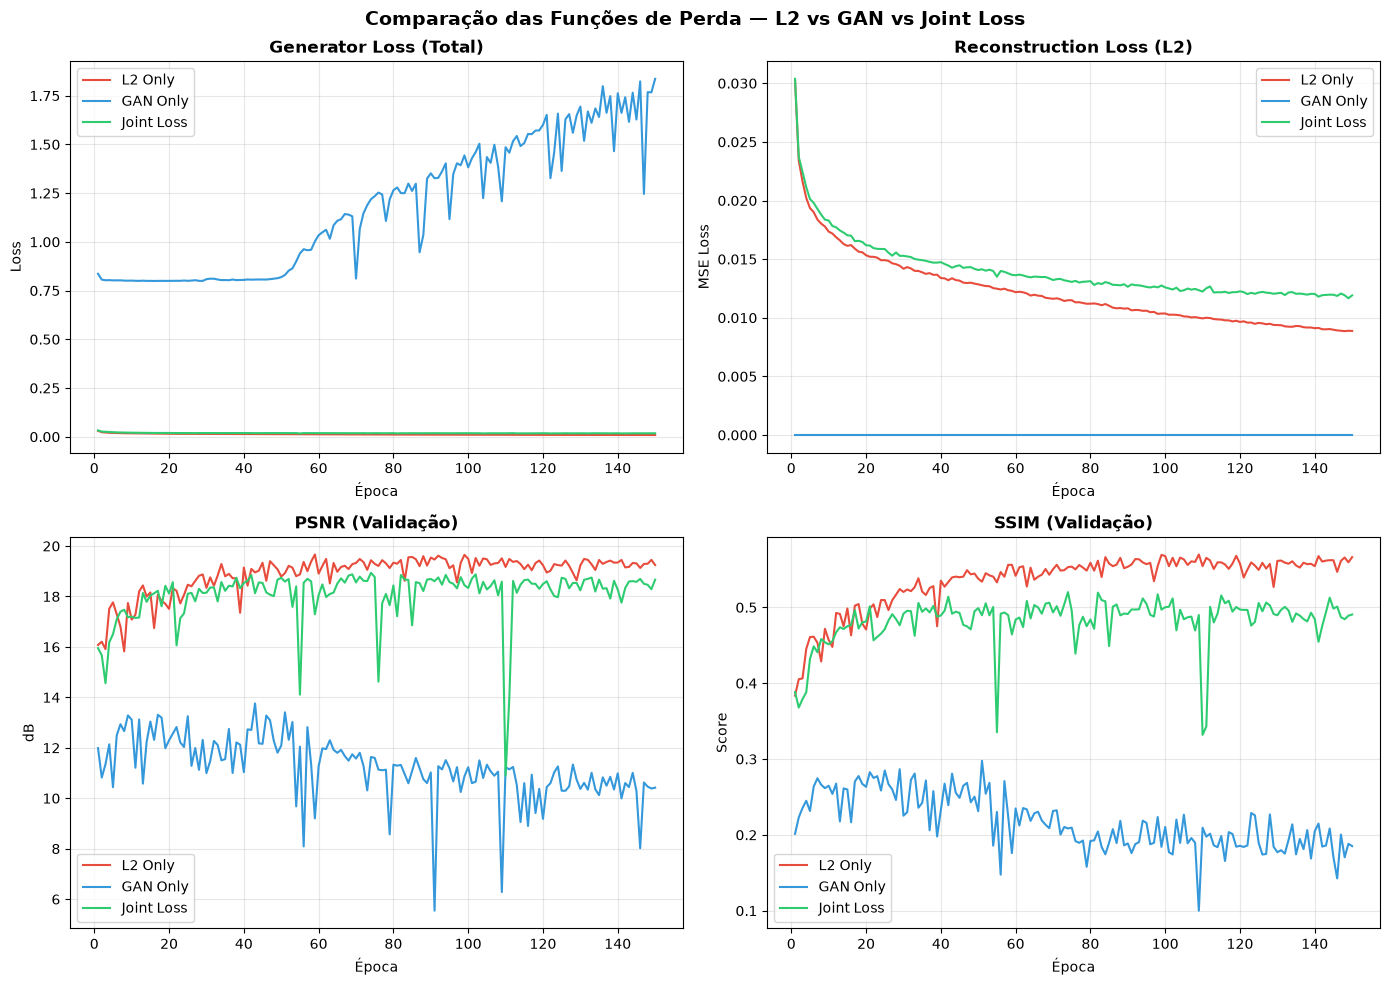

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
colors = {'L2 Only': '#e74c3c', 'GAN Only': '#3498db', 'Joint Loss': '#2ecc71'}

for name, h in results.items():
    epochs = range(1, len(h['val_psnr']) + 1)
    c = colors[name]
    axes[0,0].plot(epochs, h['loss_G'],   color=c, label=name)
    axes[0,1].plot(epochs, h['loss_rec'], color=c, label=name)
    axes[1,0].plot(epochs, h['val_psnr'], color=c, label=name)
    axes[1,1].plot(epochs, h['val_ssim'], color=c, label=name)

for ax, title, ylabel in zip(
    axes.flat,
    ['Generator Loss (Total)', 'Reconstruction Loss (L2)', 'PSNR (Validação)', 'SSIM (Validação)'],
    ['Loss', 'MSE Loss', 'dB', 'Score']
):
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Época')
    ax.set_ylabel(ylabel)
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle('Comparação das Funções de Perda — L2 vs GAN vs Joint Loss', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{SAVE_ROOT}/loss_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

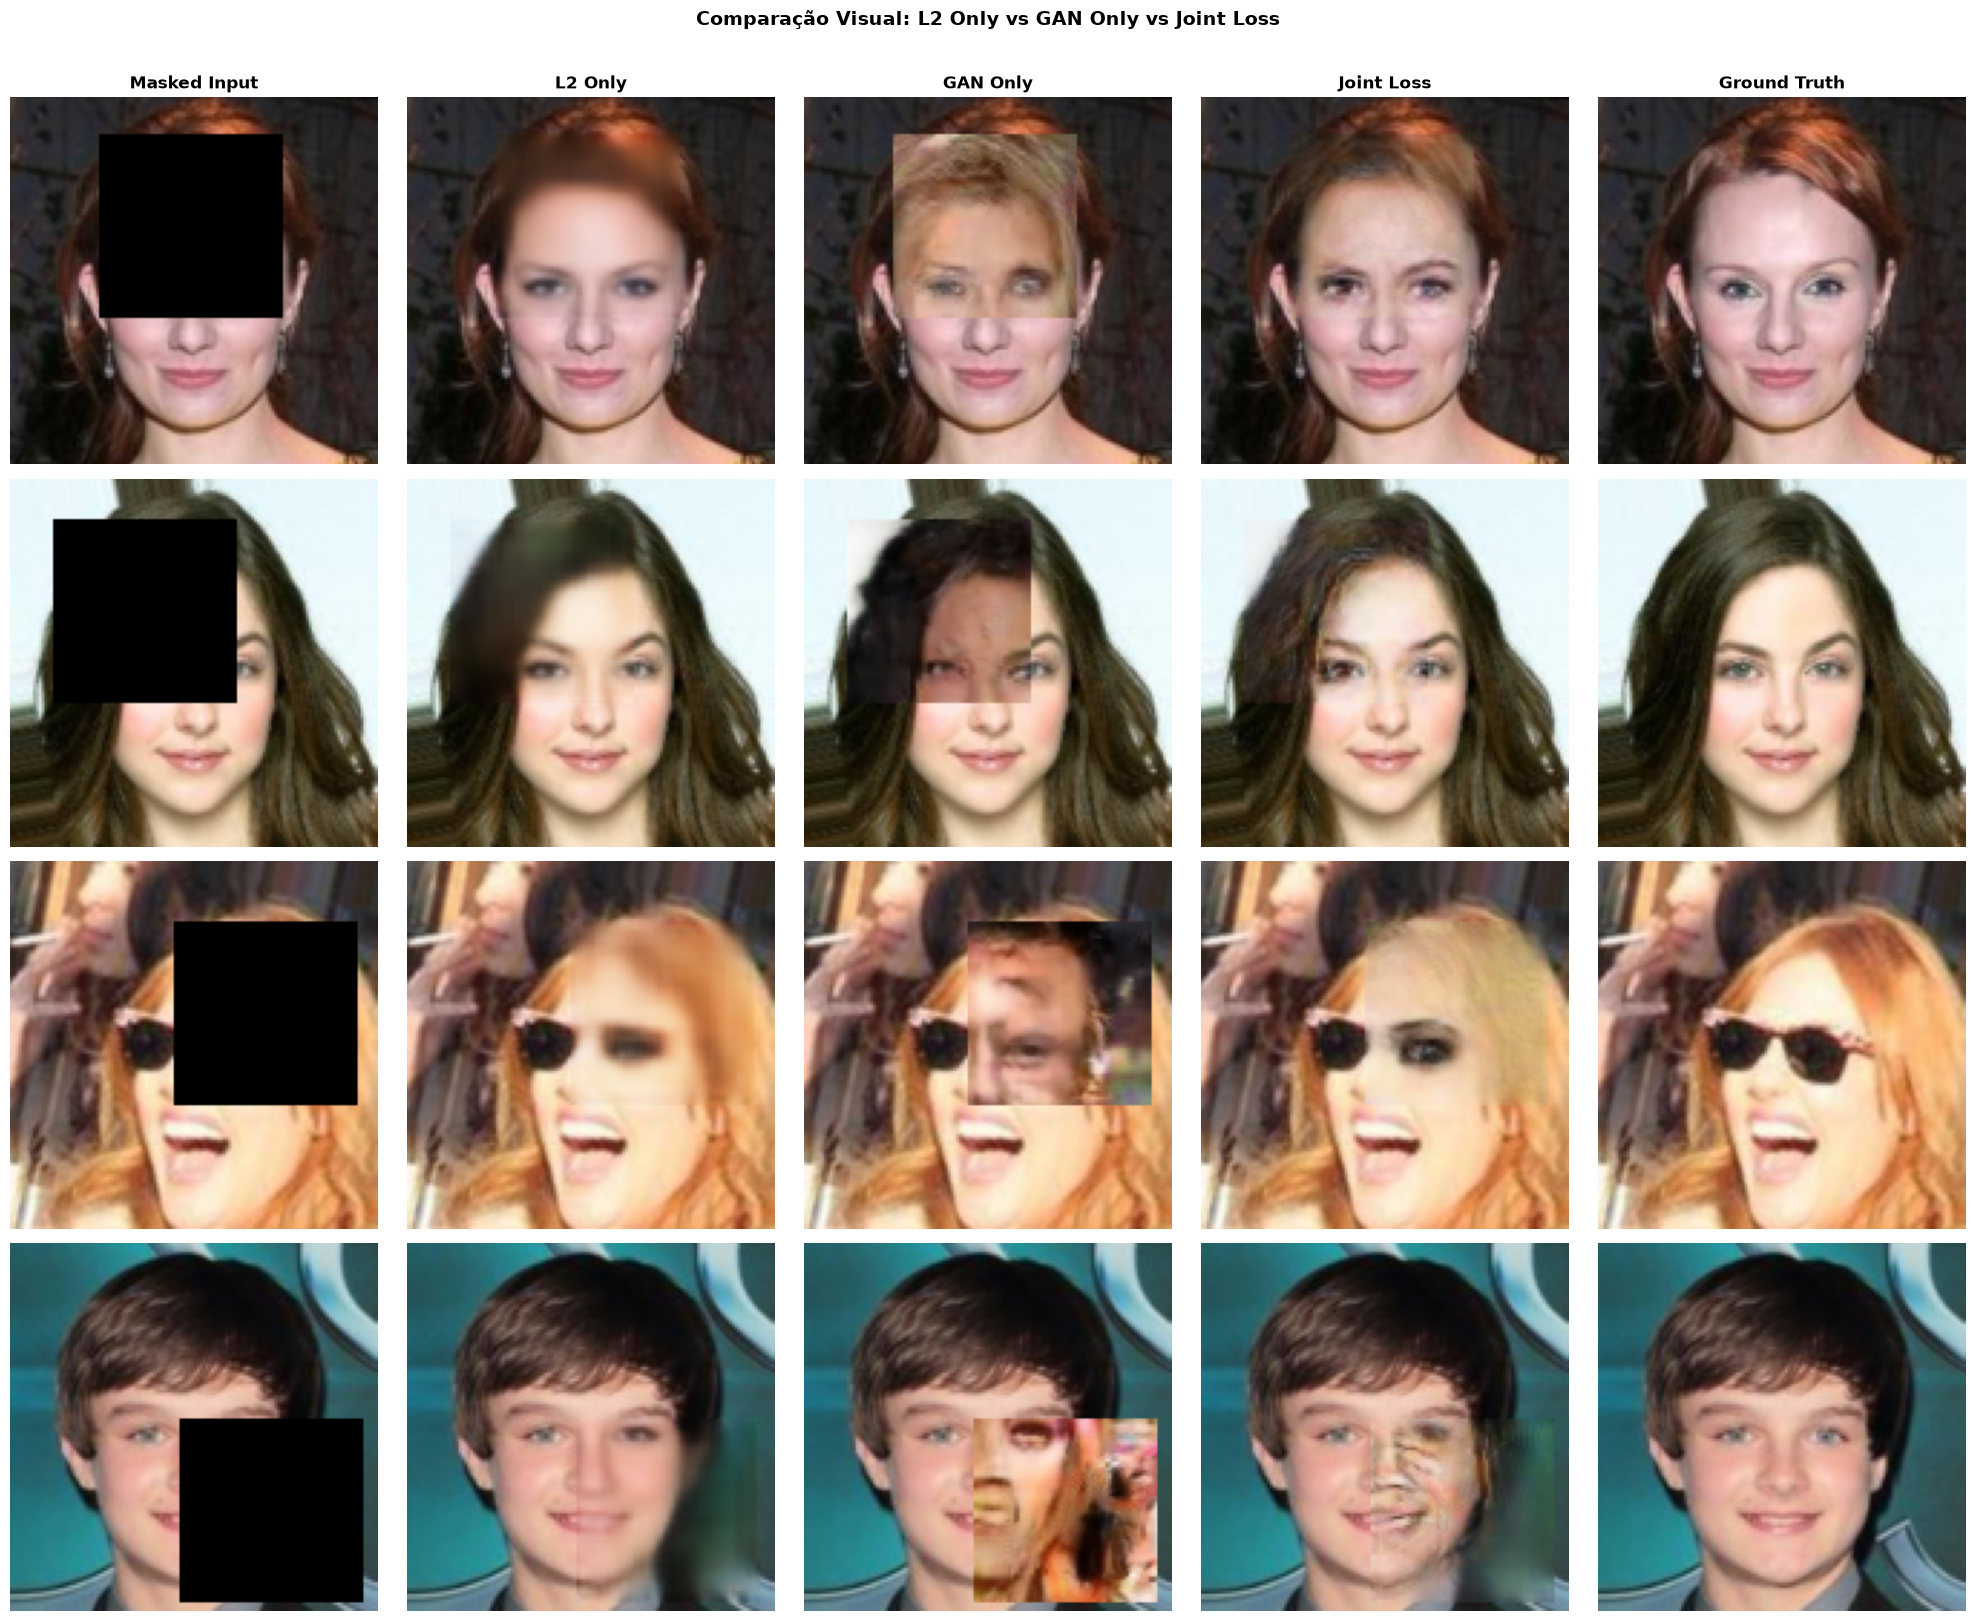

In [14]:
@torch.no_grad()
def compare_models_visual(models_dict, loader, n_samples=4):
    """Grelha visual: Masked Input | <modelos> | Ground Truth"""
    masked, original, mask, _ = next(iter(loader))
    masked   = masked[:n_samples].to(DEVICE)
    original = original[:n_samples].to(DEVICE)
    mask     = mask[:n_samples].to(DEVICE)

    outputs = {}
    for name, model in models_dict.items():
        model.eval()
        fake = model(masked)
        completed = original * (1 - mask) + fake * mask
        outputs[name] = denorm(completed).cpu()

    fig, axes = plt.subplots(n_samples, len(models_dict) + 2,
                              figsize=(4 * (len(models_dict) + 2), 4 * n_samples))
    col_titles = ['Masked Input'] + list(models_dict.keys()) + ['Ground Truth']

    for i in range(n_samples):
        col = 0
        axes[i, col].imshow(denorm(masked[i]).cpu().permute(1,2,0).numpy())
        if i == 0: axes[i, col].set_title(col_titles[col], fontweight='bold')
        axes[i, col].axis('off')
        col += 1

        for name in models_dict.keys():
            axes[i, col].imshow(outputs[name][i].permute(1,2,0).numpy())
            if i == 0: axes[i, col].set_title(col_titles[col], fontweight='bold')
            axes[i, col].axis('off')
            col += 1

        axes[i, col].imshow(denorm(original[i]).cpu().permute(1,2,0).numpy())
        if i == 0: axes[i, col].set_title('Ground Truth', fontweight='bold')
        axes[i, col].axis('off')

    plt.suptitle('Comparação Visual: L2 Only vs GAN Only vs Joint Loss', fontsize=14, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.savefig(f'{SAVE_ROOT}/visual_comparison.png', dpi=150, bbox_inches='tight')
    plt.show()


compare_models_visual({'L2 Only': G_l2, 'GAN Only': G_gan, 'Joint Loss': G_joint}, val_loader)

## 12. Discussão dos Resultados

### 12.1 Correções face à primeira versão

A primeira versão deste projeto sofreu de vários problemas identificados durante um treino de teste. Esta secção documenta as causas e as correções aplicadas antes do treino final de 150 épocas.

1. **Artefacto "checkerboard"** nos resultados GAN Only e Joint Loss — causado pelo `ConvTranspose2d` com kernel 4/stride 2 no decoder, que produz sobreposições desiguais durante o upsampling. Resolvido substituindo por `Upsample(nearest) + Conv2d`.

2. **Campo recetivo desajustado do PatchGAN** — o discriminador tinha um campo recetivo fixo de 94×94 px, que em imagens de 64×64 equivalia a ver quase a imagem inteira em cada avaliação — comportamento de discriminador global, não local. Com máscaras de 32×32, isto forçava o gerador a produzir padrões repetitivos de alta frequência (o efeito "tartan"). Corrigido com profundidade adaptativa ao `IMG_SIZE`.

3. **Calibração do peso adversarial** — com o PatchGAN corrigido e genuinamente local, o discriminador tornou-se muito mais exigente. O valor `λ_adv=0.001` do paper original revelou-se insuficiente para este regime de treino. Após validação empírica, `λ_adv=0.002` mostrou ser o valor que permite à Joint Loss diferenciar-se da L2 sem desestabilizar o treino.

4. **Máscaras aleatórias** — a substituição das máscaras centrais fixas por máscaras de posição aleatória aumentou a dificuldade do problema e a robustez do modelo, obrigando-o a aprender a reconstruir qualquer região da imagem, não apenas o centro da face.

5. **Avaliação restrita à máscara** — as métricas PSNR e SSIM passaram a ser calculadas apenas na região reconstruída, usando as coordenadas exatas de cada máscara. Isto elimina a inflação artificial causada pelos pixéis intocados e torna a avaliação cientificamente honesta.

---

### 12.2 Análise dos resultados obtidos

Os resultados do treino final (150 épocas, 20 000 imagens CelebA a 128×128 px) revelaram padrões distintos e bem diferenciados entre os três modos:

**L2 Only** foi o modo mais estável. A loss desceu de forma monotónica e consistente ao longo de todas as épocas, terminando com PSNR ~19 dB e SSIM ~0.57. Visualmente, as reconstruções são coerentes com o contexto — o modelo preenche as regiões mascaradas com conteúdo plausível e bem integrado nas bordas — mas com uma suavidade característica da MSE: detalhes finos e texturas de alta frequência ficam ligeiramente esbatidos.

**GAN Only** foi o modo mais problemático. A Loss_G subiu continuamente de ~0.8 até ~1.75 ao longo das 150 épocas, com oscilações crescentes a partir da época 50 — sinal claro de que o discriminador foi progressivamente dominando o gerador sem que este conseguisse recuperar. O PSNR degradou-se ao longo do tempo em vez de melhorar, terminando em ~10 dB. Visualmente, os resultados confirmam a instabilidade: artefactos severos, incoerência contextual (por exemplo, cabelo de cor diferente inserido numa face de coloração distinta) e descontinuidades agressivas nas bordas da máscara. **Este resultado não é uma falha do pipeline — é um resultado científico válido**: demonstra empiricamente que, sem uma âncora de reconstrução, a GAN não consegue estabilizar com este volume de dados e este número de épocas.

**Joint Loss** comportou-se como esperado teoricamente. Estável como a L2, com perturbações pontuais de PSNR nas épocas ~55 e ~110 que refletem momentos em que o discriminador ganhou temporariamente terreno ao gerador, forçando uma reajuste. O PSNR final (~18.5 dB) ficou ligeiramente abaixo da L2, mas as reconstruções visuais são claramente as mais detalhadas das três — contornos mais nítidos, texturas mais definidas, integração contextual melhor do que o GAN e mais detalhe do que a L2.

| Modo | PSNR final | SSIM final | Qualidade visual | Estabilidade de treino |
|------|------|------|-----------------|--------------|
| L2 Only | ~19 dB | ~0.57 | Boa, suave, sem artefactos | Excelente — loss monotónica |
| GAN Only | ~10 dB | ~0.20 | Má — artefactos severos, incoerente | Falhou — Loss_G divergiu |
| Joint Loss | ~18.5 dB | ~0.50 | Melhor detalhe visual, boa integração | Boa, com perturbações pontuais |



---

### 12.3 O paradoxo PSNR vs. qualidade visual

Um resultado à primeira vista contraintuitivo: a Joint Loss é **visualmente superior** à L2, mas tem **PSNR ligeiramente inferior**. Este fenómeno está bem documentado na literatura de GANs e tem uma explicação direta.

O PSNR e o SSIM medem fidelidade pixel-a-pixel face ao ground truth. A L2 é explicitamente otimizada para minimizar essa distância, por isso ganha nestas métricas por construção. A componente adversarial da Joint Loss empurra o gerador para texturas realistas que não são necessariamente as mesmas do ground truth — um rosto diferente do original pode ser igualmente convincente, mas penaliza o PSNR. Esta divergência é precisamente a motivação para métricas perceptuais como **LPIPS** ou **FID**, que avaliam realismo percetual em vez de fidelidade pixel-a-pixel, e que seriam o passo seguinte natural numa extensão deste trabalho.

---

### 12.4 Comparação com a literatura

Pathak et al. (2016) reportam em CelebA valores de referência de **PSNR ≈ 23-25 dB** e **SSIM ≈ 0.85-0.90**, obtidos com treinos muito mais longos e datasets completos.

*Nota metodológica:* estes valores foram obtidos com máscara central fixa e avaliação na imagem completa — duas condições que diferem da nossa configuração. Nós usamos máscaras aleatórias (tarefa mais difícil) e avaliação restrita à região mascarada (métricas mais honestas mas numericamente mais baixas). A comparação de valores absolutos não é portanto direta. O que importa verificar — e que os resultados confirmam — é a **ordenação relativa** entre os três modos: Joint Loss visualmente superior à L2, GAN Only sem âncora de reconstrução a divergir. Esta ordenação está alinhada com as conclusões do paper original.

---

### 12.5 Ligação ao Pix2Pix

Este trabalho partilha a filosofia central da Pix2Pix (Isola et al., 2017): Joint Loss com componente L2/L1 + GAN, e PatchGAN como discriminador. A diferença fundamental está na natureza do input do gerador: no Pix2Pix, o gerador recebe um mapa de condição explícito (esboço, mapa semântico, imagem de outra modalidade). Aqui, o gerador recebe a imagem com uma região apagada e tem de inferir o contexto implicitamente — o que torna a tarefa estruturalmente mais ambígua e o papel do discriminador ainda mais relevante para guiar a geração para regiões plausíveis.


In [17]:
# Guarda o modelo final (Joint Loss, normalmente o de interesse principal)
torch.save(G_joint.state_dict(), f'{SAVE_ROOT}/context_encoder_joint_final.pth')
print(f'Modelo final guardado: {SAVE_ROOT}/context_encoder_joint_final.pth')

print('\n' + '='*55)
print('  SUMÁRIO FINAL')
print('='*55)
for name, h in results.items():
    print(f'  {name:<15}  PSNR={h["val_psnr"][-1]:.2f}  SSIM={h["val_ssim"][-1]:.4f}')
print('='*55)
print('  Referência (Pathak 2016):  PSNR~24  SSIM~0.87')
print('='*55)

Modelo final guardado: ./outputs/context_encoder_joint_final.pth

  SUMÁRIO FINAL
  L2 Only          PSNR=19.25  SSIM=0.5663
  GAN Only         PSNR=10.42  SSIM=0.1851
  Joint Loss       PSNR=18.66  SSIM=0.4906
  Referência (Pathak 2016):  PSNR~24  SSIM~0.87
